# Tuinenkaart, vereenvoudigd: van alle percelen naar tuinen binnen de kom

Dit notebook laat zien hoe `data/tuinen_kom.gpkg` tot stand komt, zonder de omwegen en tussenversies van `4_tuinenkaart_maken.ipynb`. Het idee is een trechter: **we beginnen met alle kadastrale percelen en halen er stap voor stap dingen af**.

| stap | wat gaat eraf | bron |
|---|---|---|
| 1 | niets: alle percelen | BRK (kadaster) |
| 2 | percelen zonder woonpand | BAG woonpanden |
| 3 | percelen die veel te groot zijn voor het huis erop (> 20 × de pandoppervlakte) | BRK + BAG |
| 4 | percelen met een woonpand van na 2013 (nieuwbouw: in 2014 was daar nog geen tuin) | BAG bouwjaar |
| 5 | alles buiten de bebouwde kom | TOP10NL woonkernen |
| 6 | landbouwgrond (weiland, akker, boom- en fruitteelt) | BGT |
| 7 | de gebouwen zelf (huis, schuur, garage) | BAG alle panden |

Stap 2 tot en met 4 gooien **hele percelen** weg (het aantal vlakken daalt). Stap 5 tot en met 7 **knippen stukken** uit de percelen die overblijven (het aantal blijft ongeveer gelijk, de hectares dalen).

**Om het overzichtelijk en snel te houden draaien we alles voor één vierkante kilometer** (in Huissen, op de rand van de kom). Onderaan vergelijken we het resultaat met hetzelfde vierkant uit de landelijke `tuinen_kom.gpkg`. Voor heel Nederland zijn de stappen precies hetzelfde. Het enige verschil is dat je ze dan per gemeente herhaalt, omdat 8,4 miljoen percelen niet in één keer in het geheugen passen.

In [1]:
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import shapely

warnings.filterwarnings('ignore', message='.*keep_geom_type.*')   # overlay meldt weggevallen lijn-restjes

# Brondata (allemaal in RD-coördinaten, EPSG:28992)
PAD_PERCELEN   = Path('data/BRK/percelen.gpkg')           # alle kadastrale percelen van Nederland
PAD_WOONPANDEN = Path('data/BAG/woonpanden.gpkg')         # BAG-panden met een woonfunctie, met bouwjaar
PAD_PANDEN     = Path('data/BAG/bag-light.gpkg')          # alle BAG-panden (laag 'pand')
PAD_LANDBOUW   = Path('data/BGT/agrarisch_bos.gpkg')      # BGT-vlakken grasland agrarisch, bouwland, boom- en fruitteelt
PAD_KOM        = Path('data/top10nl_woonkernen.gpkg')     # TOP10NL-woonkernen = de bebouwde kom

PAD_UIT        = Path('data/tuinen_kom_vierkant.gpkg')    # resultaat voor dit ene vierkant
PAD_REFERENTIE = Path('data/tuinen_kom.gpkg')             # de landelijke kaart uit 4_tuinenkaart_maken.ipynb

# Het testgebied: één vierkante kilometer in Huissen
X, Y = 191_000, 439_000
GEBIED = shapely.box(X, Y, X + 1000, Y + 1000)

# Hoe de trechter er bij elke stap voor staat, voor het overzicht onderaan
trechter = []


def toon(blijft, voor, titel):
    """Kaartje: wat blijft in groen, wat er in deze stap af gaat in grijs. Telt ook mee in de trechter."""
    fig, ax = plt.subplots(figsize=(6, 6))
    valt_af = voor.overlay(blijft, how='difference')
    if len(valt_af):
        valt_af.plot(ax=ax, color='lightgrey', edgecolor='white', linewidth=0.3)
    blijft.plot(ax=ax, color='seagreen', edgecolor='white', linewidth=0.3)
    gpd.GeoSeries([GEBIED]).boundary.plot(ax=ax, color='black', linewidth=1)
    ax.set_xlim(X - 50, X + 1050); ax.set_ylim(Y - 50, Y + 1050); ax.set_axis_off()
    ax.set_title(titel)
    plt.show()
    ha = blijft.area.sum() / 10_000
    trechter.append({'stap': titel, 'vlakken': len(blijft), 'hectare': round(ha, 1)})
    print(f'{titel}: {len(blijft):,} vlakken, {ha:,.1f} ha  (er gaat {voor.area.sum() / 10_000 - ha:,.1f} ha af)')

## Stap 1: alle percelen

We lezen alle kadastrale percelen die het vierkant raken. Ze blijven voorlopig heel, ook als ze over de rand van het vierkant steken, want stap 3 heeft de oppervlakte van het hele perceel nodig. Daarom is het totaal hier meer dan 100 ha.

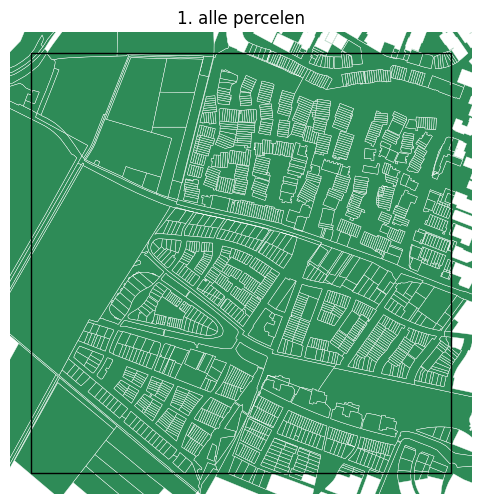

1. alle percelen: 1,873 vlakken, 164.7 ha  (er gaat 0.0 ha af)


In [2]:
percelen = gpd.read_file(PAD_PERCELEN, mask=GEBIED)
toon(percelen, percelen, '1. alle percelen')

## Stap 2: alleen percelen met een woonpand

We leggen de woonpanden over de percelen en berekenen per paar (perceel, pand) hoeveel vierkante meter ze overlappen. Een perceel zonder overlap heeft geen woning en valt af.

Waarom de overlap in m² en niet gewoon "raakt het perceel een pand"? De grenzen in BAG en BRK liggen net niet precies op elkaar. Een huis steekt daardoor vaak een paar centimeter in het perceel van de buren. In stap 3 en 4 telt zo'n randje dan nauwelijks mee.

De tabel `overlap` gebruiken we ook in stap 3 en 4.

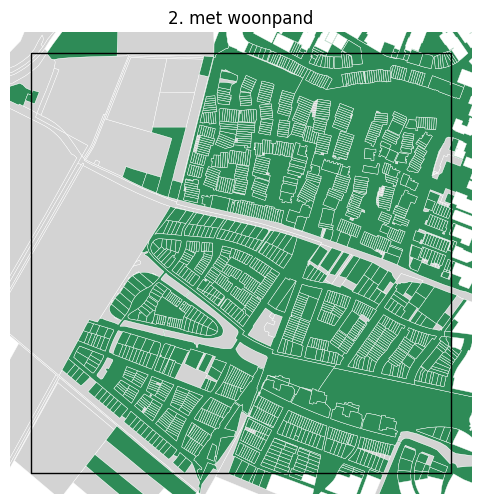

2. met woonpand: 1,580 vlakken, 98.6 ha  (er gaat 66.1 ha af)


In [3]:
woonpanden = gpd.read_file(PAD_WOONPANDEN, bbox=tuple(percelen.total_bounds), columns=['bouwjaar'])

overlap = gpd.overlay(percelen[['identificatie', 'geometry']], woonpanden, how='intersection')
overlap['m2'] = overlap.area
woonpand_m2 = overlap.groupby('identificatie')['m2'].sum()     # m² woonpand per perceel

met_woonpand = percelen[percelen['identificatie'].isin(woonpand_m2.index)]
toon(met_woonpand, percelen, '2. met woonpand')

## Stap 3: geen percelen die veel te groot zijn voor het huis

Sommige percelen zijn enorm: een boerderij met al het weiland eromheen, een park met een dienstwoning, een bedrijfsterrein met één bedrijfswoning. Dat zijn geen tuinen. Een vaste grens in m² werkt slecht, want een gedeelde binnentuin van een appartementencomplex is ook groot. De **verhouding** onderscheidt ze wel: een perceel mag hoogstens 20 keer zo groot zijn als de woonpandoppervlakte erop. Zo niet, dan valt het hele perceel af.

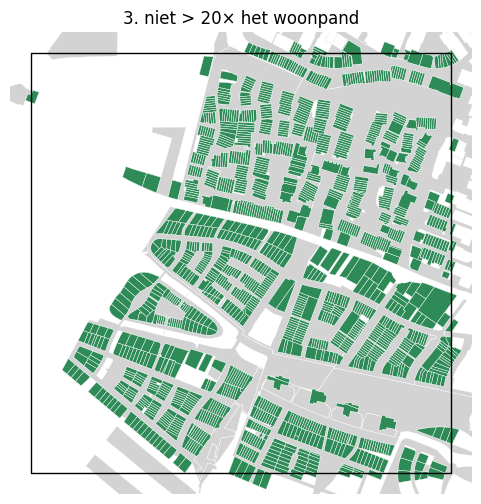

3. niet > 20× het woonpand: 1,538 vlakken, 36.6 ha  (er gaat 62.0 ha af)


In [4]:
verhouding = met_woonpand.area / met_woonpand['identificatie'].map(woonpand_m2)
niet_te_groot = met_woonpand[verhouding <= 20]
toon(niet_te_groot, met_woonpand, '3. niet > 20× het woonpand')

## Stap 4: geen nieuwbouw van na 2013

De kaart is bedoeld om boomkroon in 2014 met die in 2024 te vergelijken. In een wijk die na 2013 is gebouwd bestond de tuin in 2014 nog niet. Daarom valt een perceel af als er een woonpand met bouwjaar 2014 of later op staat. Een overlap van minder dan 1 m² telt niet mee (de grensruis uit stap 2).

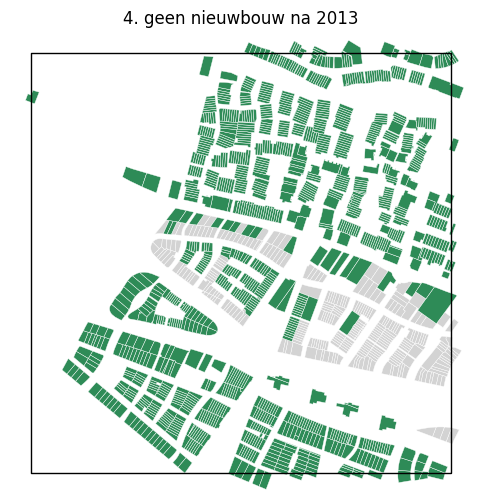

4. geen nieuwbouw na 2013: 1,233 vlakken, 29.3 ha  (er gaat 7.3 ha af)


In [5]:
nieuwbouw = overlap.loc[(overlap['bouwjaar'] > 2013) & (overlap['m2'] >= 1), 'identificatie']
geen_nieuwbouw = niet_te_groot[~niet_te_groot['identificatie'].isin(nieuwbouw)]
toon(geen_nieuwbouw, niet_te_groot, '4. geen nieuwbouw na 2013')

## Stap 5: alleen binnen de bebouwde kom

Vanaf hier knippen we in de percelen in plaats van ze heel weg te gooien. De kom is alle TOP10NL-woonkernen samen. We knippen meteen ook op het vierkant. Dat hoort niet bij de methode: het houdt alleen dit voorbeeld binnen de kilometer. (Landelijk knip je hier op de gemeentegrens, zodat een perceel op een grens niet in twee gemeenten terechtkomt.)

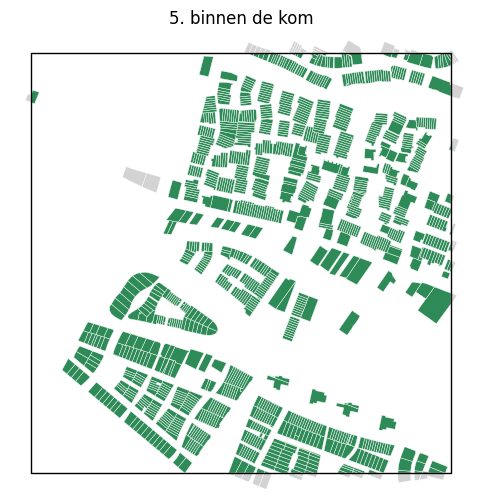

5. binnen de kom: 1,231 vlakken, 27.9 ha  (er gaat 1.5 ha af)


In [6]:
woonkernen = gpd.read_file(PAD_KOM, bbox=GEBIED.bounds)
kom = shapely.intersection(shapely.union_all(woonkernen.geometry.values), GEBIED)

in_kom = gpd.clip(geen_nieuwbouw, kom, keep_geom_type=True)
toon(in_kom, geen_nieuwbouw, '5. binnen de kom')

## Stap 6: landbouwgrond eraf

Een woonperceel kan een stuk weiland of akker bevatten. De BGT legt vast wat er feitelijk ligt. De vlakken met een landbouwkundig `fysiekVoorkomen` (grasland agrarisch, bouwland, boomteelt, fruitteelt) knippen we eruit. Bos, struiken en heide blijven staan, want dat kan gewoon tuinbeplanting zijn.

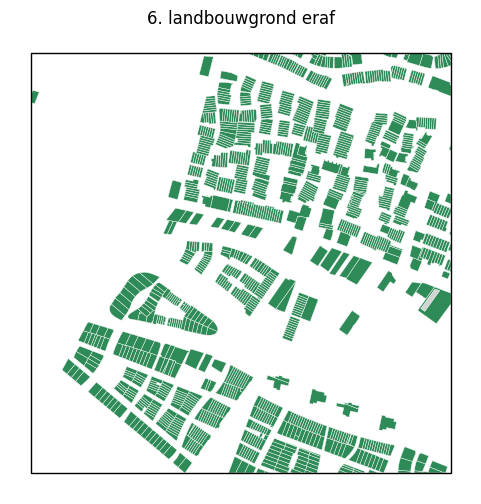

6. landbouwgrond eraf: 1,231 vlakken, 27.8 ha  (er gaat 0.1 ha af)


In [7]:
landbouw = gpd.read_file(PAD_LANDBOUW, bbox=GEBIED.bounds)
zonder_landbouw = in_kom.overlay(landbouw[['geometry']], how='difference', keep_geom_type=True)
toon(zonder_landbouw, in_kom, '6. landbouwgrond eraf')

## Stap 7: gebouwen eraf

Een dak is geen tuin. We knippen alle bestaande BAG-panden eruit, dus niet alleen het woonhuis maar ook de schuur en de garage. Panden die alleen een vergunning hebben of nog in aanbouw zijn, tellen niet mee.

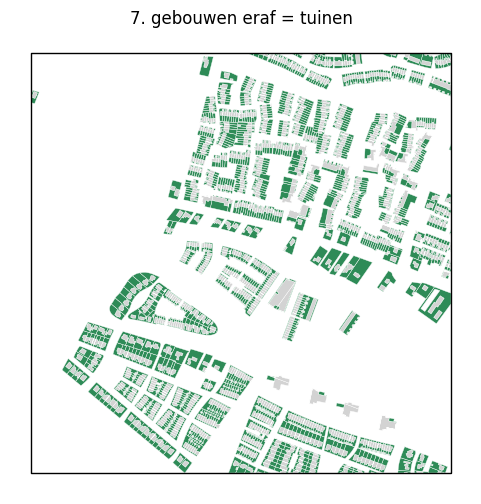

7. gebouwen eraf = tuinen: 1,231 vlakken, 17.1 ha  (er gaat 10.7 ha af)


In [8]:
BESTAAND = ['Pand in gebruik', 'Pand in gebruik (niet ingemeten)', 'Verbouwing pand',
            'Pand buiten gebruik', 'Sloopvergunning verleend']
panden = gpd.read_file(PAD_PANDEN, layer='pand', bbox=GEBIED.bounds, columns=['status'])
panden = panden[panden['status'].isin(BESTAAND)]

tuinen = zonder_landbouw.overlay(panden[['geometry']], how='difference', keep_geom_type=True)
toon(tuinen, zonder_landbouw, '7. gebouwen eraf = tuinen')

## Resultaat

De trechter in één tabel, en het resultaat opgeslagen.

In [9]:
display(pd.DataFrame(trechter))

tuinen.to_file(PAD_UIT, driver='GPKG')
print(f'Opgeslagen: {PAD_UIT}')

,stap,vlakken,hectare
0,1. alle percelen,1873,164.7
1,2. met woonpand,1580,98.6
2,3. niet > 20× het woonpand,1538,36.6
3,4. geen nieuwbouw na 2013,1233,29.3
4,5. binnen de kom,1231,27.9
5,6. landbouwgrond eraf,1231,27.8
6,7. gebouwen eraf = tuinen,1231,17.1


Opgeslagen: data\tuinen_kom_vierkant.gpkg


## Controle: komt hetzelfde uit als de landelijke kaart?

We knippen hetzelfde vierkant uit `tuinen_kom.gpkg` en leggen de twee over elkaar. In rood staat wat in maar één van de twee kaarten zit.

vereenvoudigd: 1,231 vlakken, 17.07 ha
landelijk:     1,231 vlakken, 17.07 ha
oppervlakte die maar in één van de twee zit: 0.0 m²


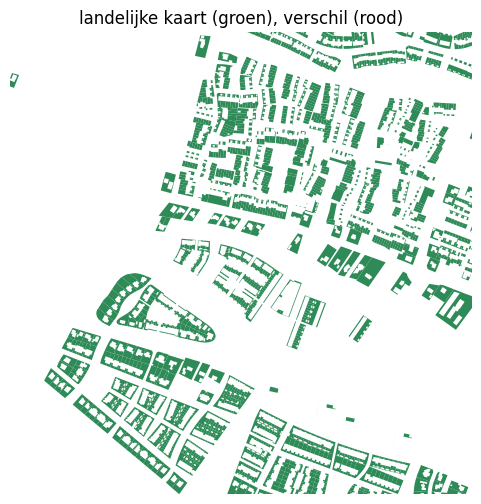

In [10]:
referentie = gpd.read_file(PAD_REFERENTIE, mask=GEBIED)
referentie['geometry'] = referentie.intersection(GEBIED)      # tuinen over de rand van het vierkant afknippen

verschil = shapely.symmetric_difference(shapely.union_all(tuinen.geometry.values),
                                        shapely.union_all(referentie.geometry.values))
print(f'vereenvoudigd: {len(tuinen):,} vlakken, {tuinen.area.sum() / 10_000:.2f} ha')
print(f'landelijk:     {len(referentie):,} vlakken, {referentie.area.sum() / 10_000:.2f} ha')
print(f'oppervlakte die maar in één van de twee zit: {verschil.area:,.1f} m²')

fig, ax = plt.subplots(figsize=(6, 6))
referentie.plot(ax=ax, color='seagreen')
gpd.GeoSeries([verschil]).plot(ax=ax, color='red')
ax.set_xlim(X, X + 1000); ax.set_ylim(Y, Y + 1000); ax.set_axis_off()
ax.set_title('landelijke kaart (groen), verschil (rood)')
plt.show()